# Four NEXRAD radars around Oklahoma City, 5 May 2022: does a mosaic close the gap to MRMS?

**Why.** On this case our single-radar (KTLX) hourly totals reached a correlation of 0.88-0.95 with the MRMS
gauge-corrected reference (radarwow-verify notebook 03), against 0.97-0.99 for MRMS radar-only, which combines
several radars and so sees each place with a lower beam. Here we combine KTLX with its neighbours Vance AFB (KVNX),
Tulsa (KINX) and Frederick (KFDR), each processed by the same single-radar chain, by beam-height quality.

**Reference.** MRMS MultiSensor QPE Pass 2 (gauge-corrected); MRMS radar-only as the peer mosaic. Scored on the
MRMS 0.01 deg grid over the area within 150 km of KTLX (where we have the single-radar result), and over the whole
mosaic area.

In [1]:
# Colab: uncomment to install
!pip install -q cfgrib eccodes pysteps opencv-python-headless rasterio "git+https://github.com/manmeet3591/radarwow-pipeline" "git+https://github.com/manmeet3591/radarwow-mosaic"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.mosaic import composite, mosaic_grid, quality_index, to_grid
from radarwow.pipeline import hourly_totals
from radarwow.verify import fetch_mrms, scores, to_mrms_grid

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
SITES = ["KTLX", "KVNX", "KINX", "KFDR"]
START, END = "2022-05-05 07:00", "2022-05-05 11:00"
rad = {s: hourly_totals(s, START, END, n_tilts=1, blockage=False) for s in SITES}
grid = mosaic_grid(list(rad.values()), res_km=1.0)
lon2, lat2 = np.meshgrid(grid.lon.values, grid.lat.values)
k = rad["KTLX"]
d_ktlx = np.hypot((lat2 - k.attrs["radar_lat"]) * 111.2, (lon2 - k.attrs["radar_lon"]) * 111.2 * np.cos(np.deg2rad(k.attrs["radar_lat"])))
q = {s: np.nan_to_num(to_grid(quality_index(r["HEIGHT"].values, r["BLOCKAGE"].values), r, grid)) for s, r in rad.items()}

In [3]:
rows, maps = [], {}
for t in rad["KTLX"]["time"].values:
    per = {s: to_grid(r["RAIN"].sel(time=t).values, r, grid) for s, r in rad.items()}
    est = {"KTLX only": per["KTLX"],
           "mosaic (max quality)": composite([per[s] for s in SITES], [q[s] for s in SITES], "max")[0],
           "mosaic (weighted)": composite([per[s] for s in SITES], [q[s] for s in SITES], "weighted")[0]}
    hb = pd.Timestamp(t) + pd.Timedelta(hours=1)
    ref = fetch_mrms("gauge_corrected", hb, f"{CACHE}/mrms")
    ro = fetch_mrms("radar_only", hb, f"{CACHE}/mrms")
    covered = np.isfinite(est["mosaic (max quality)"])
    for area, m in [("within 150 km of KTLX", (d_ktlx <= 150) & np.isfinite(per["KTLX"])), ("whole mosaic", covered)]:
        for name, f in est.items():
            if name == "KTLX only" and area == "whole mosaic":
                continue
            o, r_, _ = to_mrms_grid(np.where(m, f, np.nan), lat2, lon2, ref, None)
            rows.append(dict(hour=f"{pd.Timestamp(t):%H}-{pd.Timestamp(t).hour + 1:02d}", area=area, method=name, **scores(o, r_)))
        ones = np.where(m, 1.0, np.nan)
        _, rv, _ = to_mrms_grid(ones, lat2, lon2, ro, None)
        _, gv, _ = to_mrms_grid(ones, lat2, lon2, ref, None)
        rows.append(dict(hour=f"{pd.Timestamp(t):%H}-{pd.Timestamp(t).hour + 1:02d}", area=area, method="MRMS radar-only", **scores(rv, gv)))
    maps[t] = est | {"mrms": ref}
res = pd.DataFrame(rows)
order = ["KTLX only", "mosaic (max quality)", "mosaic (weighted)", "MRMS radar-only"]
for area, d in res.groupby("area", sort=False):
    tab = d.pivot_table(index="method", columns="hour", values=["bias_ratio", "corr", "rmse"]).round(2)
    display(Markdown(f"**{area}** (against MRMS gauge-corrected; RMSE in mm)\n\n" + tab.loc[[o for o in order if o in tab.index]].to_markdown()))

**within 150 km of KTLX** (against MRMS gauge-corrected; RMSE in mm)

| method               |   ('bias_ratio', '07-08') |   ('bias_ratio', '08-09') |   ('bias_ratio', '09-10') |   ('bias_ratio', '10-11') |   ('corr', '07-08') |   ('corr', '08-09') |   ('corr', '09-10') |   ('corr', '10-11') |   ('rmse', '07-08') |   ('rmse', '08-09') |   ('rmse', '09-10') |   ('rmse', '10-11') |
|:---------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| KTLX only            |                      1.02 |                      1    |                      1.07 |                      0.99 |                0.97 |                0.95 |                0.95 |                0.9  |                0.99 |                1.64 |                1.02 |                1.29 |
| mosaic (max quality) |                      1    |                      1    |                      1.11 |                      1.04 |                0.97 |                0.96 |                0.96 |                0.92 |                1.01 |                1.53 |                0.97 |                1.12 |
| mosaic (weighted)    |                      1.01 |                      1    |                      1.12 |                      1.04 |                0.98 |                0.96 |                0.96 |                0.92 |                0.96 |                1.51 |                0.95 |                1.13 |
| MRMS radar-only      |                      1.12 |                      1.13 |                      1.32 |                      1.25 |                0.99 |                0.99 |                0.97 |                0.97 |                0.93 |                1.06 |                1.19 |                1.05 |

**whole mosaic** (against MRMS gauge-corrected; RMSE in mm)

| method               |   ('bias_ratio', '07-08') |   ('bias_ratio', '08-09') |   ('bias_ratio', '09-10') |   ('bias_ratio', '10-11') |   ('corr', '07-08') |   ('corr', '08-09') |   ('corr', '09-10') |   ('corr', '10-11') |   ('rmse', '07-08') |   ('rmse', '08-09') |   ('rmse', '09-10') |   ('rmse', '10-11') |
|:---------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| mosaic (max quality) |                      0.9  |                      0.93 |                      1.16 |                      1.14 |                0.98 |                0.95 |                0.93 |                0.92 |                2.31 |                1.86 |                1.02 |                0.97 |
| mosaic (weighted)    |                      0.9  |                      0.93 |                      1.16 |                      1.14 |                0.98 |                0.95 |                0.93 |                0.92 |                2.31 |                1.86 |                1.01 |                0.97 |
| MRMS radar-only      |                      1.07 |                      1.13 |                      1.35 |                      1.34 |                0.99 |                0.98 |                0.96 |                0.96 |                1.35 |                1.35 |                1.14 |                0.99 |

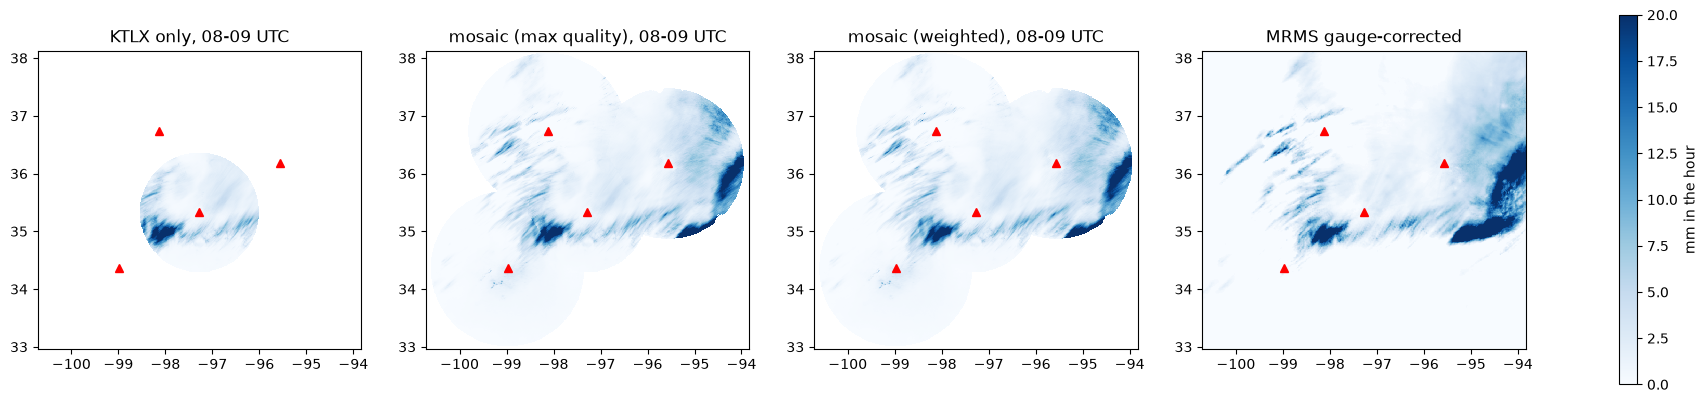

In [4]:
t = rad["KTLX"]["time"].values[1]
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
kw = dict(cmap="Blues", vmin=0, vmax=20, shading="auto")
for ax, name in zip(axes[:3], ["KTLX only", "mosaic (max quality)", "mosaic (weighted)"]):
    p = ax.pcolormesh(grid.lon, grid.lat, np.ma.masked_invalid(maps[t][name]), **kw)
    ax.set_title(f"{name}, {pd.Timestamp(t):%H}-{pd.Timestamp(t).hour + 1:02d} UTC")
ref = maps[t]["mrms"]
box = ref.sel(latitude=slice(grid.lat.max(), grid.lat.min()), longitude=slice(grid.lon.min(), grid.lon.max()))
axes[3].pcolormesh(box.longitude, box.latitude, np.ma.masked_invalid(box.values), **kw)
axes[3].set_title("MRMS gauge-corrected")
for ax in axes:
    for s, r in rad.items():
        ax.plot(r.attrs["radar_lon"], r.attrs["radar_lat"], "r^")
    ax.set(xlim=(grid.lon.min(), grid.lon.max()), ylim=(grid.lat.min(), grid.lat.max()), aspect=1 / np.cos(np.deg2rad(float(grid.lat.mean()))))
fig.colorbar(p, ax=axes, label="mm in the hour", shrink=0.8)
fig.savefig(f"{FIG}/03_oklahoma_mosaic.png", dpi=80, bbox_inches="tight")
plt.show()

## Takeaways
- **The mosaic helps a little where KTLX already sees well.** Within 150 km of KTLX, correlation with the
  gauge-corrected reference goes from 0.90-0.97 (KTLX alone) to 0.92-0.98, and RMSE falls by up to 13 % (10-11 UTC);
  bias stays near 1 (1.00-1.12), better than MRMS radar-only (1.12-1.32).
- **It does not reach MRMS's pattern agreement** (0.97-0.99 near KTLX, 0.96-0.99 over the whole area against our
  0.92-0.98). Likely reasons: MRMS mosaics rain rates every 2 minutes from more radars before accumulating, while we
  combine hourly totals; and our quality index uses beam height only (Oklahoma is flat, so no blockage).
- **Max-quality and quality-weighted composites give the same scores here.**
- **Over the whole four-radar area the mosaic underestimates the first two hours** (0.90-0.93) and overestimates the
  last two (1.14-1.16); not investigated per radar yet.